In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split


In [3]:
# ## 2. Load and explore the dataset
# Each flower has 4 **features** (measured in cm) and 1 **label** (the species).

iris = load_iris()
X = iris.data            # features, shape (150, 4)
y = iris.target          # labels 0, 1, 2
feature_names = iris.feature_names
class_names = iris.target_names.tolist()

df = pd.DataFrame(X, columns=feature_names)
df["species"] = [class_names[i] for i in y]
print(df.head())

print("Shape of X:", X.shape)
print("Classes   :", list(class_names))
print()
print(df["species"].value_counts())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
Shape of X: (150, 4)
Classes   : ['setosa', 'versicolor', 'virginica']

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


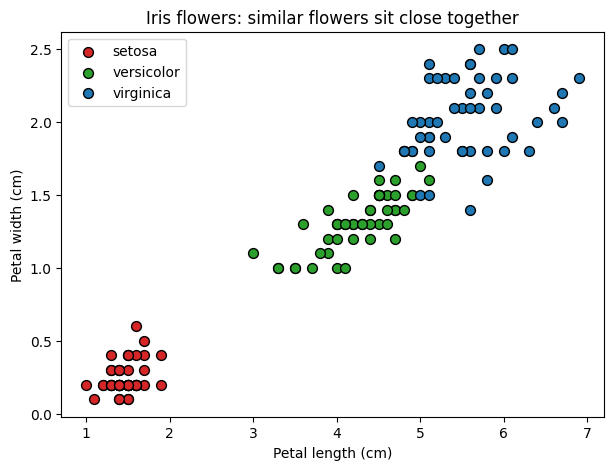

In [4]:
# The classes are perfectly balanced: 50 flowers of each species.

# ### Look at the data
# Plot two features, petal length and petal width. Can you already see the groups?

colors = ["tab:red", "tab:green", "tab:blue"]

plt.figure(figsize=(7, 5))
for label, color in zip(range(3), colors):
    mask = y == label
    plt.scatter(X[mask, 2], X[mask, 3], c=color, label=class_names[label],
                edgecolor="k", s=50)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris flowers: similar flowers sit close together")
plt.legend()
plt.show()


In [5]:
# **Key observation:** flowers of the same species sit **close to each other**.
# KNN relies on exactly this: *points that are near each other probably share the same label.*

# ## 3. Split into training and test sets
# - **Training set (80%)**: the "known" flowers KNN will remember.
# - **Test set (20%)**: flowers we hide, then ask KNN to predict, to check whether it really works.
#
# `stratify=y` keeps the same proportion of each species in both sets.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Test samples    :", len(X_test))


Training samples: 120
Test samples    : 30


In [6]:
# ---
# # Part A: KNN from scratch
#
# We build KNN in three small steps:
#
# | Step | Question | Function |
# |---|---|---|
# | 1 | How far apart are two flowers? | `euclidean_distance` |
# | 2 | Which K flowers are closest? | `get_neighbors` |
# | 3 | What label do most of them have? | `majority_vote` |

# ## Step 1: Distance between two points
#
# We use **Euclidean distance**, the ordinary straight-line distance:
#
# $$ d(\mathbf{a}, \mathbf{b}) = \sqrt{(a_1-b_1)^2 + (a_2-b_2)^2 + \dots + (a_n-b_n)^2} $$
#
# It is the Pythagoras theorem extended to more dimensions.

def euclidean_distance(a, b):
    # Straight-line distance between two points a and b.
    return np.sqrt(np.sum((a - b) ** 2))

# Small check with numbers you can verify by hand: the 3-4-5 triangle
p = np.array([0, 0])
q = np.array([3, 4])
print("Distance between (0,0) and (3,4) =", euclidean_distance(p, q))

# Distance between two real flowers
print("Flower 0 :", X_train[0], "->", class_names[y_train[0]])
print("Flower 1 :", X_train[1], "->", class_names[y_train[1]])
print("Distance :", round(euclidean_distance(X_train[0], X_train[1]), 3))


Distance between (0,0) and (3,4) = 5.0
Flower 0 : [4.4 2.9 1.4 0.2] -> setosa
Flower 1 : [4.9 2.5 4.5 1.7] -> virginica
Distance : 3.503


New flower: [4.4 3.  1.3 0.2]  (true species: setosa)

    training index  distance     species
0                0     0.141      setosa
1               93     0.245      setosa
2              119     0.300      setosa
3               58     0.300      setosa
4              116     0.361      setosa
5               49     0.424      setosa
6               50     0.424      setosa
7               40     0.469      setosa
8               15     0.469      setosa
9               89     0.510      setosa
10              44     0.510      setosa
11              80     0.548      setosa
12               3     0.557      setosa
13             114     0.640      setosa
14              47     0.640      setosa
15              23     0.671      setosa
16              48     0.714      setosa
17              29     0.787      setosa
18             115     0.794      setosa
19              27     0.806      setosa
20              63     0.825      setosa
21              70     0.831      setosa
22

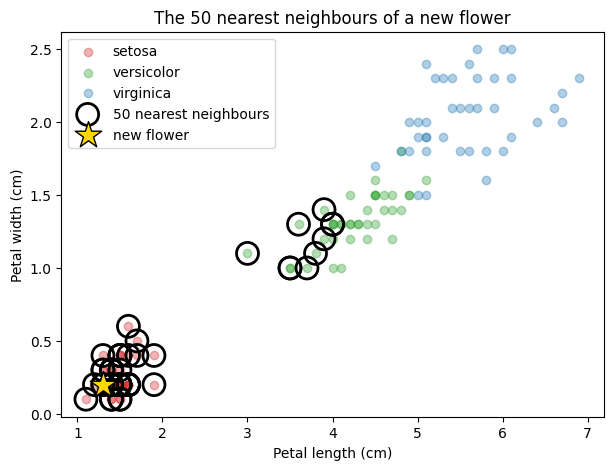

In [7]:
# ## Step 2: Find the K nearest neighbours
# For one new flower:
# 1. compute its distance to **every** training flower,
# 2. sort by distance,
# 3. keep the first K.

def get_neighbors(X_train, y_train, new_point, k):
    # Return the indices, distances and labels of the k closest training points.
    distances = [euclidean_distance(new_point, x) for x in X_train]
    distances = np.array(distances)

    nearest_idx = np.argsort(distances)[:k]   # indices of the k smallest distances
    return nearest_idx, distances[nearest_idx], y_train[nearest_idx]

# Try it on the first test flower
new_flower = X_test[0]
k = 50
idx, dists, labels = get_neighbors(X_train, y_train, new_flower, k)

print("New flower:", new_flower, " (true species:", class_names[y_test[0]] + ")\n")
print(pd.DataFrame({
    "training index": idx,
    "distance": dists.round(3),
    "species": [class_names[l] for l in labels],
}))

# ### See the neighbours on the plot

plt.figure(figsize=(7, 5))
for label, color in zip(range(3), colors):
    mask = y_train == label
    plt.scatter(X_train[mask, 2], X_train[mask, 3], c=color, alpha=0.35,
                label=class_names[label])

# circle the K neighbours
plt.scatter(X_train[idx, 2], X_train[idx, 3], s=250, facecolors="none",
            edgecolors="black", linewidths=2, label=f"{k} nearest neighbours")
# the new flower
plt.scatter(new_flower[2], new_flower[3], marker="*", s=400, c="gold",
            edgecolor="k", label="new flower", zorder=5)

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title(f"The {k} nearest neighbours of a new flower")
plt.legend()
plt.show()


In [8]:
# *Note: distances were computed with all 4 features, but we can only draw 2, so a neighbour
# may occasionally look farther away on this plot than it really is.*

# ## Step 3: Majority vote
# Count the labels of the K neighbours. The most common label wins.

def majority_vote(labels):
    # Return the most common label.
    # If two labels tie, Counter keeps the one it saw first, which is the CLOSEST neighbour
    # (labels arrive sorted by distance). That is a sensible tie-breaker.
    return Counter(labels).most_common(1)[0][0]

votes = Counter(labels)
print("Votes     :", {class_names[k_]: v for k_, v in votes.items()})
print("Prediction:", class_names[majority_vote(labels)])
print("Actual    :", class_names[y_test[0]])

# ## Put it all together: a `KNNClassifier` class
# Same three steps, wrapped in a class with `fit` and `predict`, the same interface scikit-learn uses.

class KNNClassifier:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        # "Training" = just remember the data
        self.X_train = X
        self.y_train = y
        return self

    def predict_one(self, x):
        _, _, labels = get_neighbors(self.X_train, self.y_train, x, self.k)
        return majority_vote(labels)

    def predict(self, X):
        return np.array([self.predict_one(x) for x in X])

# ## 4. Evaluate: how accurate is our KNN?

def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

my_knn = KNNClassifier(k=5)
my_knn.fit(X_train, y_train)
y_pred = my_knn.predict(X_test)

print("Predictions:", y_pred)
print("Actual     :", y_test)
print(f"\nAccuracy (from scratch, k=5): {accuracy(y_test, y_pred):.2%}")

# ---

Votes     : {'setosa': 40, 'versicolor': 10}
Prediction: setosa
Actual    : setosa
Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Actual     : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Accuracy (from scratch, k=5): 100.00%


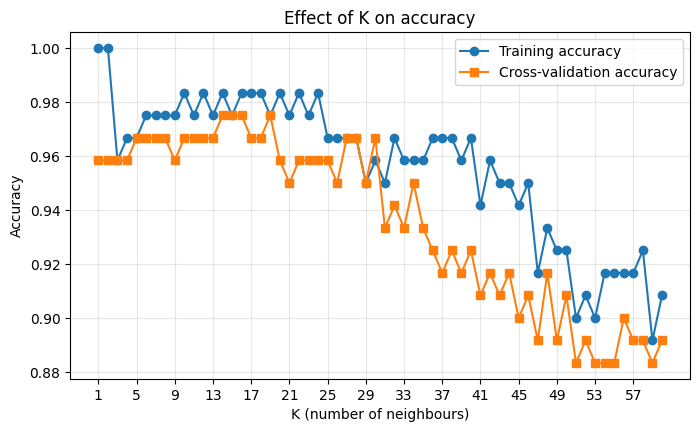

Best K by cross-validation: 14  (CV accuracy 97.50%)


In [9]:
# ---
# # Part B: Choosing K
#
# - **Small K (e.g. 1):** very sensitive to noise, since one odd neighbour decides everything → **overfitting**.
# - **Large K (e.g. 100):** the vote is swamped by far-away points from other classes → **underfitting**.
# - **Tip:** for 2 classes use an **odd** K to avoid ties.
#
# We try K = 1 … 60 and watch the accuracy.
#
# To make this fair we use **5-fold cross-validation**: the training set is split into 5 parts, each part
# takes a turn as a mini test set, and the scores are averaged. That way K is chosen without ever
# looking at the real test set.

from sklearn.model_selection import StratifiedKFold

def cv_accuracy(k, X, y, folds=5):
    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)
    scores = []
    for tr, va in skf.split(X, y):
        model = KNNClassifier(k=k).fit(X[tr], y[tr])
        scores.append(accuracy(y[va], model.predict(X[va])))
    return np.mean(scores)

k_values = range(1, 61)
train_scores, cv_scores = [], []
for k in k_values:
    model = KNNClassifier(k=k).fit(X_train, y_train)
    train_scores.append(accuracy(y_train, model.predict(X_train)))
    cv_scores.append(cv_accuracy(k, X_train, y_train))

plt.figure(figsize=(8, 4.5))
plt.plot(k_values, train_scores, "o-", label="Training accuracy")
plt.plot(k_values, cv_scores, "s-", label="Cross-validation accuracy")
plt.xlabel("K (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("Effect of K on accuracy")
plt.xticks(range(1, 61, 4))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

best_k = list(k_values)[int(np.argmax(cv_scores))]
print(f"Best K by cross-validation: {best_k}  (CV accuracy {max(cv_scores):.2%})")


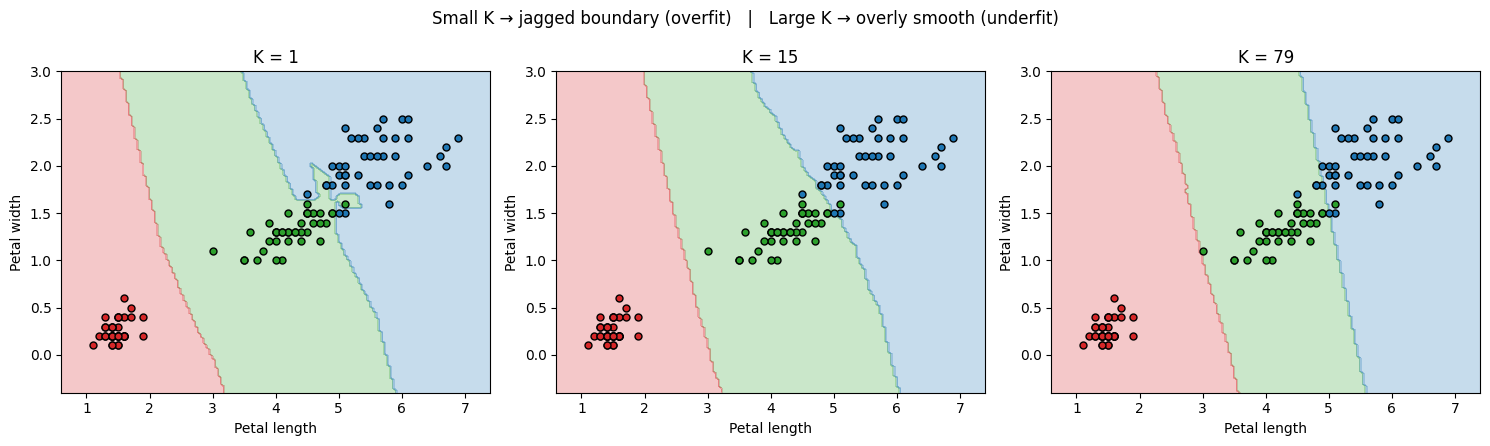

In [10]:
# **What to notice**
# - At **K = 1** training accuracy is 100%: every flower's nearest neighbour is itself. That is memorising, not learning.
# - The cross-validation curve is the honest one. Pick K where it is high and stable.

# ## Seeing K visually: decision boundaries
# We train on only **2 features** (petal length and width) so the result can be drawn.
# Each background colour shows what KNN would predict for a flower at that spot.

def plot_decision_boundary(ax, k, X2, y2):
    model = KNNClassifier(k=k).fit(X2, y2)
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150),
                         np.linspace(y_min, y_max, 150))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    from matplotlib.colors import ListedColormap
    ax.contourf(xx, yy, Z, alpha=0.25, cmap=ListedColormap(colors))
    for label, color in zip(range(3), colors):
        m = y2 == label
        ax.scatter(X2[m, 0], X2[m, 1], c=color, edgecolor="k", s=25)
    ax.set_title(f"K = {k}")
    ax.set_xlabel("Petal length")
    ax.set_ylabel("Petal width")

X2_train = X_train[:, 2:4]   # petal length and width only

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, k in zip(axes, [1, 15, 79]):
    plot_decision_boundary(ax, k, X2_train, y_train)
plt.suptitle("Small K → jagged boundary (overfit)   |   Large K → overly smooth (underfit)")
plt.tight_layout()
plt.show()
